# A1: multi-model station correction with neural operators

**Question.** Starting from two global forecasts (IFS and AIFS, 0.25°), how much do neural
operators that combine both models' fields with the latest station obs-forecast reduce the
10 m wind error at the stations, compared with the A0 methods (target-station persistence,
ridge regression, Gaussian process)?

**Setup**

* Data:
  * IFS (`ifs/0p25`) and AIFS (`aifs` experimental, `aifs-single` from 2025-02) on their
    common 0.25° grid (49 × 121, 62–74 °N, 6–36 °E), runs at 00 / 12 UTC, leads 0–66 h
    every 6 h. 1 019 runs have both models.
  * 99 Frost stations in Nordland / Troms / Finnmark with > 50 % hourly wind.
* Base forecast: the mean of IFS and AIFS, bilinear at the station.
* Target: the residual y = obs(t + τ) − base(t + τ), in (u, v).
* Information at issue time: obs-forecast of each model at init time t, i.e. obs(t) minus
  that model's run from t − 12 h at +12 h.
* Split by init:
  * train 2024-03-01 – 2024-12-31;
  * validation 2025-01 – 2025-03 (early stopping for the operators);
  * test 2025-04-01 – 2025-09-12. The test period is summer.
* Settings, as in A0:
  * **weighted stations including target**: temporal split only;
  * **weighted stations excluding target**: 5 spatially blocked station groups; each group
    is predicted by a model trained without it, from the other stations' obs-forecast.
* Metric: vector RMSE of (u, v) in m/s, per lead. All methods are scored on the same
  samples: valid target, both models' obs-forecast available at the target station, and at
  least 3 other reporting stations.

## Methods

### 1. What every method predicts

For a run initialised at t, lead τ ∈ {0, 6, …, 66} h and station s:

    base_s(t + τ)  = ½ (IFS_s(t + τ) + AIFS_s(t + τ))    both bilinear at the station
    y_s(t, τ)      = obs_s(t + τ) − base_s(t + τ)          residual, (u, v)
    forecast       = base + ŷ

Every method outputs ŷ, and every score compares base + ŷ with the station observation.

### 2. Information available at issue time

* **Model fields at the valid time**: both runs from t, on the 0.25° grid.
* **Station obs-forecast at init time**, per model m:

      d_s,m(t) = obs_s(t) − m_{t−12}(+12 h)

  The run from t is not out yet at t, so the previous run is used. This gives four numbers
  per station (u and v for IFS and AIFS), plus a flag saying whether the station reports.
* No observation after t is ever an input.

### 3. The neural operators

All come unchanged from `neuraloperator` 2.0. The Fourier, Fourier–graph and geometry-informed neural operators share:

* the same inputs and target, the same loss and training schedule;
* the same Fourier backbone: width 64, 4 layers, 16 × 32 Fourier modes on the 49 × 121 grid.

They differ only in **how the station obs-forecast enters** and **how the output is read
at the stations**.

**Grid channels** (used by all operators):

| group | channels | count |
|---|---|---|
| model fields at the valid time | IFS and AIFS: 10 m u, 10 m v, 2 m temperature, mean sea-level pressure, surface pressure, 850 hPa temperature (normalised with train mean / std) | 12 |
| time | lead / 66 h; sin, cos of valid hour; sin, cos of valid day of year | 5 |
| position | latitude, longitude (standardised) | 2 |

**Station features** (5 per station): d_IFS (u, v), d_AIFS (u, v), each divided by its
train standard deviation, and the availability flag (0 where the station does not report
or is hidden). Unavailable stations have zero features.

#### Fourier neural operator (`FNO`)

1. The station features are rasterised onto the grid: each station goes to its nearest
   0.25° cell, cells with several stations take the mean, and a fifth channel marks cells
   that contain a reporting station. This adds 5 grid channels, 24 in total.
2. `FNO`: lifting → 4 Fourier layers (global convolution in spectral space plus a local
   linear path) → projection to 2 channels, with 10 % domain padding because the domain is
   not periodic. The output is a residual field (u, v) on the grid.
3. The field is read at each station by bilinear interpolation.

#### Fourier–graph neural operator (`FNOGNO`)

1. The same 24 grid channels as the Fourier neural operator.
2. Fourier layers on the grid give a latent vector at every grid point.
3. A graph neural operator computes the output at each station as a learned kernel
   integral over the grid points within 60 km:

       ŷ(s) = mean over grid points g with |x_s − x_g| < 60 km of  κ(x_s, x_g) · h(g)

   Here κ is a small network of the two positions (sinusoidal embeddings), and the result
   is projected to (u, v). This replaces fixed bilinear interpolation with a learned
   readout, which can adapt to the offset between the station and the grid cells.

#### Geometry-informed neural operator (`GINO`)

1. **Input graph neural operator**: the 5 station features enter as a point cloud at the
   true station positions. Each grid point integrates the stations within 120 km with a
   learned kernel (a kernel-weighted mean of the station features, 5 channels on the grid). There is no rasterisation, and stations
   that share a cell stay distinct.
2. The 19 model-field / time / position channels are appended as latent features.
3. Fourier layers on the grid.
4. **Output graph neural operator** (60 km) to the station positions, as in the
   Fourier–graph neural operator.

This is the structure closest to the paper's set-of-observations → any-location design,
with graph kernel integrals in place of attention.

#### Further grid operators from `neuraloperator`

These take the same 24 grid channels as the Fourier neural operator, return a residual
field on the grid, and are read at the stations by bilinear interpolation. Only the
operator in the middle changes.

* **Tucker-factorised Fourier neural operator** (`TFNO`): the Fourier neural operator with
  its spectral weights stored as a Tucker decomposition (rank 0.42). It has fewer
  parameters, which may help with only 10 months of training data.
* **U-shaped neural operator** (`UNO`): 5 Fourier layers.
  * Resolution: full → half → half → full → full.
  * Width: 64 → 128 → 128 → 128 → 64 channels.
  * Skip connections join layers of equal resolution, so large-scale and fine-scale
    structure are handled at different levels.
* **Spherical Fourier neural operator** (`SFNO`): spherical-harmonic convolutions instead
  of the planar Fourier transform. It assumes a global equiangular grid, which the
  regional 0.25° patch is not, so it is included only as a reference.
* **Local neural operator** (`LocalNO`): each Fourier layer also has two local branches.
  * A local integral kernel (DISCO convolution).
  * A finite-difference (differential) kernel.

  These target sharp, local gradients such as those around coasts and terrain. The grid is
  padded by 4 cells by replication, so the periodic local convolutions do not join the two
  sides of the domain. The domain length is set so that the cell spacing is equal in both
  directions.
* **Codomain attention neural operator** (`CODANO`): every input channel is a token, and
  each layer mixes the 24 channel fields by attention across channels, with Fourier
  convolutions inside the tokens. A 1 × 1 convolution maps the per-channel outputs to
  (u, v). It is the only attention-based operator here and is reported for completeness.
  It is slow, so it is trained for 15 epochs.

#### Uncertainty-quantification neural operator (`UQNO`)

This operator does not make a new point forecast. It wraps the trained Fourier neural
operator (frozen) and trains a copy of it to predict the radius of the vector error at
each station:

* loss: the pinball loss at quantile 0.9;
* calibration: split-conformal on the validation set, i.e. the radius is scaled so that
  90 % of validation errors fall inside it;
* reported: test coverage and mean radius (section 5).

Coordinates for the graph neural operators are kilometres on a local equirectangular
plane around 21 °E, 68 °N, divided by 1000.

### 4. Training

* One model for all leads, with lead given as an input channel. Samples are
  (run, lead) pairs: about 7 100 for training and 1 160 for validation.
* Loss: mean over target stations of the squared vector error of the residual, normalised
  by its train standard deviation. This is the quantity behind the RMSE metric.
* AdamW (weight decay 1e-4), one-cycle learning rate with peak 1e-3, batch 16, 40 epochs,
  gradient clipping at 1. The epoch with the lowest validation loss is kept.
* **Weighted stations including target**: all reporting stations are inputs, and every
  station with an observation at t + τ is a target. One model.
* **Weighted stations excluding target**: 5 spatially blocked station groups
  (k-means on position, the same groups as the baselines). For group k, one model is
  trained on the other 4 groups only.
  * During training, each sample hides a random 25 % of the available stations from the
    input, and the loss is computed only on those hidden stations. The operator
    therefore learns to predict at locations whose own observation it cannot see.
  * At test time, all stations outside group k are inputs, and group k is predicted.

  This gives 5 models per operator, and the predictions of the 5 groups are put together.

### 5. Baselines (from A0, on the same base and samples)

| method | what it uses |
|---|---|
| `IFS`, `AIFS`, `Mean of IFS and AIFS` | raw forecasts at the station |
| `Target-station persistence` | β_τ × the target station's mean obs-forecast (β_τ fitted per lead) |
| `Ridge regression, weighted stations including / excluding target` | linear regression per lead on IFS u, v and AIFS u, v at the target, the inverse-distance-weighted mean of the other stations' obs-forecast, [the target's own obs-forecast], time, altitude |
| `Station-wise ridge regression on IFS and AIFS wind [and target obs-forecast]` | a separate ridge regression per station and lead on IFS u, v and AIFS u, v at that station [and its own obs-forecast]; needs the station's own training history, so only in the "including target" setting |
| `Gaussian process with elevation / distance only, ...` | spatial Gaussian process of the mean obs-forecast at t (Matérn 5/2 in distance [× Gaussian in elevation difference]), posterior mean at the target × ρ_τ; for "excluding", kernel and ρ_τ are refitted per group |

### 6. Evaluation

* Vector RMSE of (u, v) against the station observations at t + τ, on the test runs
  (2025-04-01 – 2025-09-12).
* All methods are scored on the same samples.
* Tables show the change vs `Mean of IFS and AIFS`; negative means a lower RMSE.


In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '..')
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from windcast.station_correction import SpatialGP, idw, station_groups, crps_gauss
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
ROOT = Path('/cluster/work/projects/nn8106k/siyan/windcast')
d = dict(np.load(ROOT / 'cache/multimodel_2024-03-01_2025-09-12.npz', allow_pickle=True))
inits, leads = pd.DatetimeIndex(d['inits']), d['leads']
fc = d['st_fc'].astype(float)                       # (N, L, M, S, 2)
N, L, M, S, _ = fc.shape
tindex = pd.Index(d['time']); ti = tindex.get_indexer(inits)
obs = d['obs'].astype(float)
o_valid = np.stack([obs[ti + ld] for ld in leads], 1)
base = fc.mean(2)
y = o_valid - base
prev = pd.Index(inits).get_indexer(inits - pd.Timedelta(hours=12))
omf = np.full((N, M, S, 2), np.nan)                 # obs-forecast at init, per model
ok = prev >= 0
omf[ok] = obs[ti[ok]][:, None] - fc[prev[ok], list(leads).index(12)]
d0 = omf.mean(1)                                    # mean over models
xy, z = d['xy'].astype(float), d['masl'].astype(float)
groups = station_groups(xy)
def span(a, b): return np.asarray((inits >= a) & (inits <= pd.Timestamp(b) + pd.Timedelta(hours=12)) & d['keep'])
tr, va, te = span('2024-03-01', '2024-12-31'), span('2025-01-01', '2025-03-31'), span('2025-04-01', '2025-09-12')
own_ok = np.isfinite(omf).all((1, 3))               # (N, S)
nother = own_ok.sum(1)[:, None] - 1
base_mask = own_ok & (nother >= 3)
TEST = base_mask[:, None, :] & np.isfinite(y[..., 0]) & te[:, None, None]
print(f'{N} runs: train {tr.sum()}, val {va.sum()}, test {te.sum()}; {S} stations; group sizes', np.bincount(groups))
print('test samples per lead:', TEST.sum((0, 2)))

1019 runs: train 592, val 97, test 330; 99 stations; group sizes [28 17 14 20 20]
test samples per lead: [30881 30510 30631 30470 30619 30451 30590 30435 30582 30420 30560 30405]


## 1. Baselines (A0 methods on the multi-model base)

In [2]:
P, V = {}, {}
NAMES = dict(
    ifs='IFS', aifs='AIFS', mean='Mean of IFS and AIFS', tsp='Target-station persistence',
    rin='Ridge regression, weighted stations including target', rex='Ridge regression, weighted stations excluding target',
    gin='Gaussian process with elevation, weighted stations including target',
    gex='Gaussian process with elevation, weighted stations excluding target',
    gdx='Gaussian process distance only, weighted stations excluding target',
    )
OPS = {'fno': 'Fourier neural operator', 'tfno': 'Tucker-factorised Fourier neural operator',
       'uno': 'U-shaped neural operator', 'sfno': 'Spherical Fourier neural operator',
       'localno': 'Local neural operator', 'codano': 'Codomain attention neural operator',
       'fnogno': 'Fourier–graph neural operator', 'gino': 'Geometry-informed neural operator'}
for op, nm in OPS.items():
    NAMES[op + '_in'] = nm + ', weighted stations including target'
    NAMES[op + '_ex'] = nm + ', weighted stations excluding target'
P[NAMES['ifs']] = fc[:, :, 0] - base
P[NAMES['aifs']] = fc[:, :, 1] - base
P[NAMES['mean']] = np.zeros_like(y)
I = idw(xy, d0)
hour = np.array([(inits + pd.Timedelta(hours=int(l))).hour for l in leads]).T
doy = np.array([(inits + pd.Timedelta(hours=int(l))).dayofyear for l in leads]).T
def feats(j, own_in):
    rep = lambda a: np.repeat(a[:, None], S, 1)
    cols = [fc[:, j, 0, :, 0], fc[:, j, 0, :, 1], fc[:, j, 1, :, 0], fc[:, j, 1, :, 1], I[..., 0], I[..., 1],
            rep(np.sin(2*np.pi*hour[:, j]/24)), rep(np.cos(2*np.pi*hour[:, j]/24)),
            rep(np.sin(2*np.pi*doy[:, j]/366)), rep(np.cos(2*np.pi*doy[:, j]/366)), np.broadcast_to(z, (N, S))]
    if own_in:
        cols += [omf[:, 0, :, 0], omf[:, 0, :, 1], omf[:, 1, :, 0], omf[:, 1, :, 1]]
    return np.stack(cols, -1)
for k in ['tsp', 'rin', 'rex']:
    P[NAMES[k]] = np.full_like(y, np.nan)
for j in range(L):
    yj = y[:, j]
    m_tr = base_mask & np.isfinite(yj[..., 0]) & tr[:, None]
    m_te = base_mask & np.isfinite(yj[..., 0]) & te[:, None]
    b = np.sum(d0[m_tr] * yj[m_tr]) / np.sum(d0[m_tr] ** 2)
    P[NAMES['tsp']][:, j][m_te] = b * d0[m_te]
    for key, own_in in [('rin', True), ('rex', False)]:
        X = feats(j, own_in)
        grp = [(np.ones(S, bool), np.ones(S, bool))] if own_in else [(groups != k, groups == k) for k in range(5)]
        for s_tr, s_te in grp:
            mt, me = m_tr & s_tr[None], m_te & s_te[None]
            sc = StandardScaler().fit(X[mt])
            for c in range(2):
                out = P[NAMES[key]][:, j, :, c]
                out[me] = Ridge(alpha=1.0).fit(sc.transform(X[mt]), yj[mt][:, c]).predict(sc.transform(X[me]))
print('ridge and persistence done')

# station-wise ridge regression (a separate linear model per station and lead; only possible where
# the station has its own training history, i.e. in the "including target" setting)
NAMES['srm'] = 'Station-wise ridge regression on IFS and AIFS wind'
NAMES['sro'] = 'Station-wise ridge regression on IFS and AIFS wind and target obs-forecast'
P[NAMES['srm']] = np.full_like(y, np.nan); P[NAMES['sro']] = np.full_like(y, np.nan)
for j in range(L):
    yj = y[:, j]
    m_tr = base_mask & np.isfinite(yj[..., 0]) & tr[:, None]
    m_te = base_mask & np.isfinite(yj[..., 0]) & te[:, None]
    for s_ in range(S):
        a_, b_ = m_tr[:, s_], m_te[:, s_]
        if b_.sum() == 0:
            continue
        X1 = fc[:, j, :, s_].reshape(N, -1)
        X2 = np.concatenate([X1, omf[:, :, s_].reshape(N, -1)], 1)
        for key, X in [('srm', X1), ('sro', X2)]:
            for c in range(2):
                out = P[NAMES[key]][:, j, :, c]
                out[b_, s_] = Ridge(alpha=1.0).fit(X[a_], yj[a_, s_, c]).predict(X[b_]) if a_.sum() >= 30 else 0.0
print('station-wise ridge done')

ridge and persistence done


station-wise ridge done


In [3]:
# Gaussian processes on the mean obs-forecast at init time
def fit_post(use_z, drop=None):
    g = SpatialGP(xy, z, use_z=use_z)
    dd = d0[tr].copy()
    if drop is not None: dd[:, drop] = np.nan
    hp, _ = g.fit(dd)
    return hp, g.posterior(d0)
hp_all, post_all = fit_post(True)
print('distance x elevation, all stations:', {k: round(float(v), 2) for k, v in hp_all.items()})
fold_e = [fit_post(True, groups == k) for k in range(5)]
fold_d = [fit_post(False, groups == k) for k in range(5)]
for k in ['gin', 'gex', 'gdx']:
    P[NAMES[k]] = np.full_like(y, np.nan); V[NAMES[k]] = np.full(y.shape[:-1], np.nan)
def gp_fill(name, pm, pv, s_tr, s_te):
    for j in range(L):
        yj = y[:, j]
        mt = base_mask & np.isfinite(yj[..., 0]) & tr[:, None] & s_tr[None] & np.isfinite(pm[..., 0])
        me = base_mask & np.isfinite(yj[..., 0]) & te[:, None] & s_te[None] & np.isfinite(pm[..., 0])
        r = np.sum(pm[mt] * yj[mt]) / np.sum(pm[mt] ** 2)
        e = np.mean((yj[mt] - r * pm[mt]) ** 2) - r ** 2 * np.mean(pv[mt])
        P[name][:, j][me] = r * pm[me]; V[name][:, j][me] = r ** 2 * pv[me] + max(e, 1e-3)
allst = np.ones(S, bool)
gp_fill(NAMES['gin'], *post_all['including_target'], allst, allst)
for k in range(5):
    gp_fill(NAMES['gex'], *fold_e[k][1]['excluding_target'], groups != k, groups == k)
    gp_fill(NAMES['gdx'], *fold_d[k][1]['excluding_target'], groups != k, groups == k)
print('Gaussian processes done')

distance x elevation, all stations: {'sf2': 2.83, 'ell_km': 342.02, 'sn2': 5.57, 'ell_z_m': 342.33}


Gaussian processes done


## 2. Neural operators (trained on the GPU nodes, `windcast/training/train_station_operator.py`)

In [4]:
RUNS = ROOT / 'runs_a1'
info = []
for op in OPS:
    kin, kex = NAMES[op + '_in'], NAMES[op + '_ex']
    f = RUNS / f'{op}_including_s0' / 'pred.npz'
    if f.exists():
        P[kin] = np.load(f)['test'].astype(float)
        h = json.loads((f.parent / 'history.json').read_text()); info.append((kin, h['n_params'], h['best_val'], len(h['history'])))
    parts = [RUNS / f'{op}_excluding_g{k}_s0' / 'pred.npz' for k in range(5)]
    if all(p.exists() for p in parts):
        acc = np.full_like(y, np.nan)
        for k, p in enumerate(parts):
            pk = np.load(p)
            assert (pk['groups'] == groups).all(), 'station groups differ'
            acc[:, :, groups == k] = pk['test'][:, :, groups == k]
        P[kex] = acc
        h = [json.loads((p.parent / 'history.json').read_text()) for p in parts]
        info.append((kex, h[0]['n_params'], float(np.mean([x['best_val'] for x in h])), len(h[0]['history'])))
pd.set_option('display.max_colwidth', 90)
display(pd.DataFrame(info, columns=['method', 'parameters', 'best validation loss (normalised, mean over groups)', 'epochs']))
missing = [NAMES[op + s_] for op in OPS for s_ in ('_in', '_ex') if NAMES[op + s_] not in P]
print('missing operator runs:', missing)

,method,parameters,"best validation loss (normalised, mean over groups)",epochs
0,"Fourier neural operator, weighted stations including target",4510146,1.532659,40
1,"Fourier neural operator, weighted stations excluding target",4510146,2.526658,40
2,"Tucker-factorised Fourier neural operator, weighted stations including target",1975122,1.541598,40
3,"Tucker-factorised Fourier neural operator, weighted stations excluding target",1975122,2.530446,40
4,"U-shaped neural operator, weighted stations including target",8851778,1.618848,40
5,"U-shaped neural operator, weighted stations excluding target",8851778,2.543093,40
6,"Spherical Fourier neural operator, weighted stations including target",577986,1.508370,40
7,"Spherical Fourier neural operator, weighted stations excluding target",577986,2.547489,40
8,"Local neural operator, weighted stations including target",4722754,1.516955,40
9,"Local neural operator, weighted stations excluding target",4722754,2.628868,40


missing operator runs: []


## 3. Results: vector RMSE per lead (test, 2025-04 – 09)

In [5]:
def table(mask):
    rows = {}
    for k, p in P.items():
        r = []
        for j in range(L):
            m = mask[:, j]
            e = y[:, j][m] - p[:, j][m]
            r.append(np.sqrt((e ** 2).sum(-1).mean()) if np.isfinite(e).all() else np.nan)
        rows[k] = r
    return pd.DataFrame(rows, index=pd.Index(leads, name='lead (h)')).T
R = table(TEST)
ref = R.loc[NAMES['mean']]
imp = (1 - R / ref) * 100
print('vector RMSE (m/s)'); display(R.round(2))
print('change vs Mean of IFS and AIFS (%), negative = better'); display((-imp).round(1))

vector RMSE (m/s)


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
IFS,3.37,3.38,3.44,3.46,3.51,3.51,3.55,3.58,3.66,3.68,3.75,3.82
AIFS,3.38,3.41,3.46,3.47,3.51,3.51,3.55,3.56,3.62,3.63,3.68,3.70
Mean of IFS and AIFS,3.36,3.36,3.40,3.42,3.45,3.45,3.49,3.51,3.56,3.58,3.62,3.67
Target-station persistence,0.77,2.91,3.22,3.30,3.36,3.40,3.45,3.47,3.51,3.54,3.59,3.63
"Ridge regression, weighted stations including target",0.74,2.88,3.17,3.25,3.30,3.34,3.38,3.42,3.45,3.49,3.53,3.58
"Ridge regression, weighted stations excluding target",3.28,3.31,3.35,3.38,3.40,3.42,3.44,3.47,3.52,3.54,3.58,3.64
Station-wise ridge regression on IFS and AIFS wind,2.63,2.59,2.68,2.70,2.76,2.77,2.85,2.87,2.97,2.99,3.07,3.13
Station-wise ridge regression on IFS and AIFS wind and target obs-forecast,0.71,2.50,2.67,2.69,2.76,2.78,2.86,2.88,2.98,3.00,3.08,3.14
"Gaussian process with elevation, weighted stations including target",2.81,3.09,3.26,3.33,3.38,3.41,3.45,3.47,3.52,3.55,3.60,3.63
"Gaussian process with elevation, weighted stations excluding target",3.13,3.20,3.31,3.36,3.41,3.43,3.46,3.49,3.54,3.56,3.61,3.65


change vs Mean of IFS and AIFS (%), negative = better


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
IFS,0.4,0.7,1.2,1.2,1.7,1.6,1.9,2.2,2.8,3.0,3.4,4.1
AIFS,0.6,1.5,1.7,1.6,1.7,1.7,1.8,1.6,1.6,1.4,1.6,1.0
Mean of IFS and AIFS,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
Target-station persistence,-76.9,-13.3,-5.3,-3.3,-2.6,-1.5,-1.0,-1.0,-1.5,-1.1,-0.8,-1.0
"Ridge regression, weighted stations including target",-78.0,-14.2,-6.8,-4.8,-4.4,-3.1,-3.0,-2.5,-3.2,-2.5,-2.6,-2.3
"Ridge regression, weighted stations excluding target",-2.4,-1.3,-1.4,-1.0,-1.4,-1.0,-1.3,-0.9,-1.2,-0.9,-1.3,-0.8
Station-wise ridge regression on IFS and AIFS wind,-21.6,-22.8,-21.2,-21.0,-19.9,-19.7,-18.3,-18.1,-16.7,-16.5,-15.3,-14.6
Station-wise ridge regression on IFS and AIFS wind and target obs-forecast,-78.9,-25.4,-21.6,-21.3,-20.1,-19.5,-18.0,-17.9,-16.4,-16.2,-15.0,-14.4
"Gaussian process with elevation, weighted stations including target",-16.2,-7.8,-4.2,-2.6,-2.0,-1.1,-1.1,-0.9,-1.1,-0.9,-0.8,-0.9
"Gaussian process with elevation, weighted stations excluding target",-6.6,-4.5,-2.6,-1.6,-1.2,-0.6,-0.7,-0.6,-0.7,-0.5,-0.5,-0.5


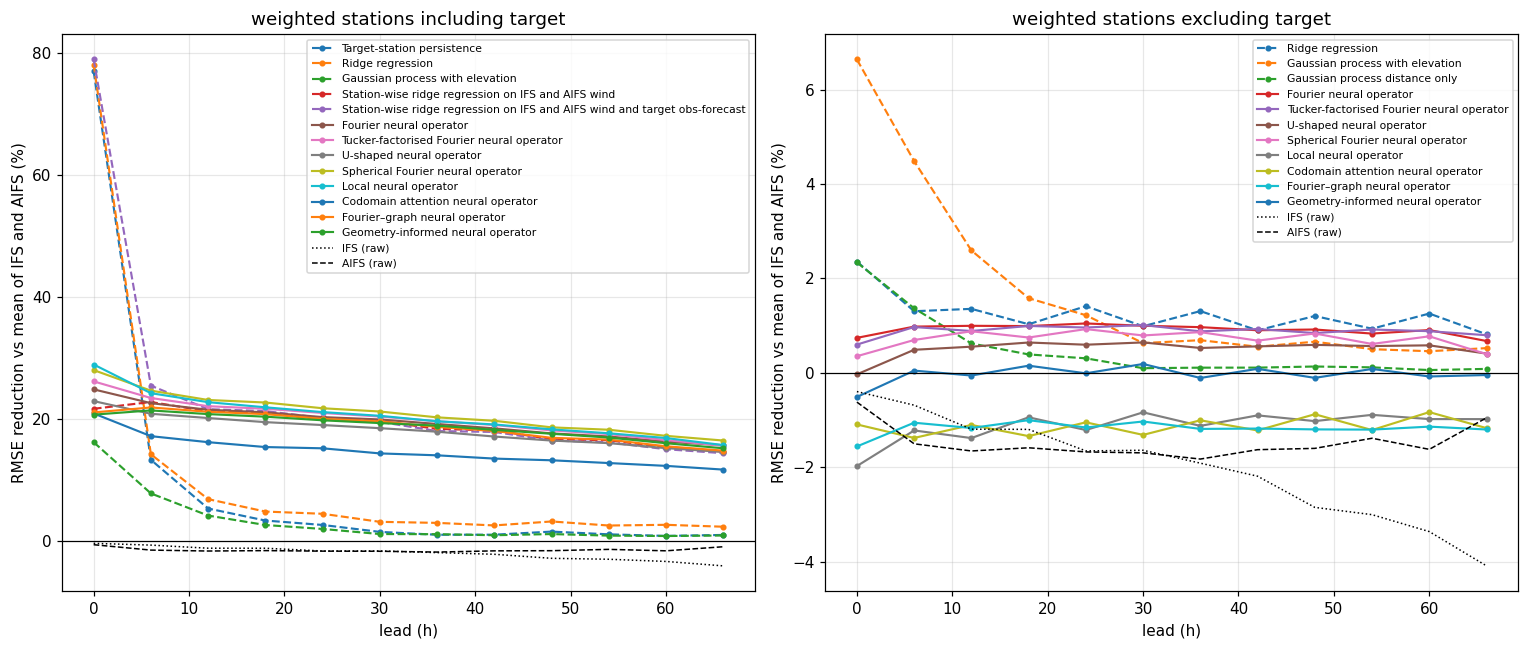

In [6]:
groups_plot = [('including target', ['tsp', 'rin', 'gin', 'srm', 'sro'] + [op + '_in' for op in OPS]),
               ('excluding target', ['rex', 'gex', 'gdx'] + [op + '_ex' for op in OPS])]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
for ax, (title, keys) in zip(axes, groups_plot):
    for k in keys:
        n = NAMES[k]
        if n in imp.index:
            ax.plot(leads, imp.loc[n], marker='.', lw=1.4, ls='-' if k[-3:] in ('_in', '_ex') else '--', label=n.split(', weighted')[0])
    for k, ls in [('ifs', ':'), ('aifs', '--')]:
        ax.plot(leads, imp.loc[NAMES[k]], 'k' + ls, lw=1, label=NAMES[k] + ' (raw)')
    ax.axhline(0, c='k', lw=.8); ax.set(title='weighted stations ' + title, xlabel='lead (h)', ylabel='RMSE reduction vs mean of IFS and AIFS (%)')
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. High winds (observed speed ≥ 10 m/s)

In [7]:
spd = np.linalg.norm(o_valid, axis=-1)
HW = TEST & (spd >= 10)
print('high-wind test samples per lead:', HW.sum((0, 2)))
Rh = table(HW)
display((-(1 - Rh / Rh.loc[NAMES['mean']]) * 100).round(1))

high-wind test samples per lead: [1808 1768 1802 1762 1794 1733 1759 1701 1733 1687 1717 1651]


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
IFS,0.3,-1.4,-1.9,-1.9,-1.8,-2.0,-2.1,-1.7,-0.9,-0.4,0.2,0.9
AIFS,-0.0,2.2,2.9,2.9,3.2,3.3,3.4,3.2,2.7,2.1,1.9,1.2
Mean of IFS and AIFS,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
Target-station persistence,-85.1,-23.7,-12.3,-7.2,-4.5,-3.6,-2.8,-2.4,-2.7,-2.3,-2.2,-2.3
"Ridge regression, weighted stations including target",-85.5,-25.6,-16.0,-11.1,-9.2,-7.9,-7.7,-6.3,-7.3,-5.9,-6.7,-5.3
"Ridge regression, weighted stations excluding target",-6.4,-5.3,-5.7,-5.1,-5.5,-4.7,-5.1,-4.1,-4.8,-3.8,-4.5,-3.1
Station-wise ridge regression on IFS and AIFS wind,-37.5,-37.5,-36.5,-35.4,-34.8,-33.4,-33.5,-31.1,-31.2,-28.8,-29.5,-25.8
Station-wise ridge regression on IFS and AIFS wind and target obs-forecast,-85.8,-41.2,-37.2,-35.9,-35.0,-33.6,-33.2,-31.0,-31.3,-28.6,-29.4,-25.9
"Gaussian process with elevation, weighted stations including target",-31.0,-15.8,-9.4,-5.7,-3.7,-2.8,-2.4,-2.1,-2.2,-2.0,-1.8,-1.8
"Gaussian process with elevation, weighted stations excluding target",-14.3,-9.0,-5.6,-3.3,-2.2,-1.4,-1.3,-1.2,-1.3,-1.1,-1.0,-0.9


## 5. Uncertainty-quantification neural operator: calibrated 90 % radius around the Fourier neural operator

The uncertainty-quantification neural operator keeps the trained Fourier neural operator
frozen and trains a copy of it to predict the radius of the vector error at each station,
with the pinball loss at quantile 0.9. The radius is then scaled (split-conformal
calibration on the validation set) so that 90 % of validation errors fall inside it. The
table shows the coverage on the test set and the mean radius; the Gaussian processes'
90 % intervals (per component, from their predictive variance) are shown for comparison.

In [8]:
rows = []
for s_, tag in [('including', 'weighted stations including target'), ('excluding', 'weighted stations excluding target')]:
    files = [RUNS / 'uqno_including_s0' / 'pred.npz'] if s_ == 'including' else [RUNS / f'uqno_excluding_g{k}_s0' / 'pred.npz' for k in range(5)]
    if not all(f.exists() for f in files):
        print('missing', tag); continue
    rad = np.full(y.shape[:-1], np.nan); pt = np.full_like(y, np.nan)
    for k, f in enumerate(files):
        z_ = np.load(f); sel = np.ones(S, bool) if s_ == 'including' else groups == k
        rad[:, :, sel] = z_['radius_test'][:, :, sel]; pt[:, :, sel] = z_['test'][:, :, sel]
    err = np.linalg.norm(y - pt, axis=-1)
    for j in [0, 1, 2, 4, 8, 11]:
        m = TEST[:, j] & np.isfinite(rad[:, j])
        rows.append(dict(setting=tag, lead=int(leads[j]), coverage=np.mean(err[:, j][m] <= rad[:, j][m]), mean_radius_ms=np.mean(rad[:, j][m])))
if rows:
    display(pd.DataFrame(rows).pivot(index='lead', columns='setting').round(3))

coverage                                     \
setting weighted stations excluding target weighted stations including target   
lead                                                                            
0                                    0.918                              0.901   
6                                    0.920                              0.896   
12                                   0.920                              0.892   
24                                   0.920                              0.893   
48                                   0.916                              0.889   
66                                   0.911                              0.885   

                            mean_radius_ms                                     
setting weighted stations excluding target weighted stations including target  
lead                                                                           
0                                    5.652                              3.769  
6                                    5.630                              3.784  
12                                   5.734                              3.871  
24                                   5.841                              3.979  
48                                   6.050                              4.195  
66                                   6.173                              4.337

## 6. Operator by operator

In [9]:
rows = []
chg = -imp
chg_h = (Rh / Rh.loc[NAMES['mean']] - 1) * 100
ninfo = {r[0]: (r[1], r[3]) for r in info}
for op, nm in OPS.items():
    kin, kex = NAMES[op + '_in'], NAMES[op + '_ex']
    if kin not in P:
        continue
    row = {'operator': nm, 'parameters (M)': round(ninfo.get(kin, (np.nan,))[0] / 1e6, 2)}
    for l in [6, 24, 48, 66]:
        row[f'incl. +{l} h'] = chg.loc[kin, l]
    for l in [6, 24, 48]:
        row[f'excl. +{l} h'] = chg.loc[kex, l] if kex in chg.index else np.nan
    row['high wind incl. +6 h'] = chg_h.loc[kin, 6]
    row['high wind excl. +6 h'] = chg_h.loc[kex, 6] if kex in chg_h.index else np.nan
    rows.append(row)
for k in ['srm', 'sro', 'rin', 'rex', 'gin', 'gex']:
    n = NAMES[k]; row = {'operator': '(baseline) ' + n}
    for l in [6, 24, 48, 66]:
        row[f'incl. +{l} h'] = chg.loc[n, l] if 'excluding' not in n else np.nan
    for l in [6, 24, 48]:
        row[f'excl. +{l} h'] = chg.loc[n, l] if 'excluding' in n else np.nan
    row['high wind incl. +6 h'] = chg_h.loc[n, 6] if 'excluding' not in n else np.nan
    row['high wind excl. +6 h'] = chg_h.loc[n, 6] if 'excluding' in n else np.nan
    rows.append(row)
print('change in vector RMSE vs Mean of IFS and AIFS (%), negative = better')
display(pd.DataFrame(rows).set_index('operator').round(1))

change in vector RMSE vs Mean of IFS and AIFS (%), negative = better


,parameters (M),incl. +6 h,incl. +24 h,incl. +48 h,incl. +66 h,excl. +6 h,excl. +24 h,excl. +48 h,high wind incl. +6 h,high wind excl. +6 h
operator,,,,,,,,,,
Fourier neural operator,4.5,-22.6,-20.3,-17.6,-15.7,-1.0,-1.0,-0.9,-37.8,-2.8
Tucker-factorised Fourier neural operator,2.0,-23.4,-21.0,-18.1,-15.6,-1.0,-1.0,-0.8,-41.0,-3.2
U-shaped neural operator,8.8,-20.8,-19.0,-16.4,-14.6,-0.5,-0.6,-0.6,-35.7,-4.0
Spherical Fourier neural operator,0.6,-24.6,-21.7,-18.6,-16.4,-0.7,-0.9,-0.8,-40.1,-4.0
Local neural operator,4.7,-24.2,-21.1,-18.3,-15.7,1.2,1.2,1.0,-41.0,-2.6
Codomain attention neural operator,0.0,-17.2,-15.2,-13.2,-11.7,1.4,1.0,0.9,-34.5,-0.7
Fourier–graph neural operator,4.6,-21.9,-20.0,-16.9,-14.8,1.1,1.2,1.2,-37.8,-2.5
Geometry-informed neural operator,4.6,-21.4,-19.8,-17.6,-15.2,-0.0,0.0,0.1,-38.8,-3.5
(baseline) Station-wise ridge regression on IFS and AIFS wind,NaN,-22.8,-19.9,-16.7,-14.6,NaN,NaN,NaN,-37.5,NaN


## 7. Findings

Numbers are changes in vector RMSE vs the mean of IFS and AIFS on the test period
(2025-04 – 09); negative is better.

1. **Including the target station, every operator gains 15–25 % at every lead**, e.g.
   −21 to −25 % at +6 h and −15 to −16 % at +66 h. The best are the local and spherical
   Fourier neural operators (−24.2 / −24.6 % at +6 h, −15.7 / −16.4 % at +66 h), followed
   by the Tucker-factorised Fourier neural operator. The codomain attention neural operator
   is the weakest (−17.2 % at +6 h, −11.7 % at +66 h): with 0.02 M parameters and about
   29 min per epoch it could only be trained for 10 epochs at batch 6.
2. **That gain is almost entirely a station-specific linear correction of the model wind,
   not information from the obs-forecast.**
   * A separate ridge regression per station on IFS and AIFS u, v gets −22.8 % at +6 h,
     −19.9 % at +24 h, −16.7 % at +48 h and −14.6 % at +66 h.
   * Subtracting each station's mean bias only gets −2 %, so it is a station-dependent
     scaling / turning of the wind (sheltering, channelling), not an offset.
   * The operators can learn it because the station positions are fixed: the raster cell
     and the position channels identify each station.
   * Over the station-wise ridge regression, the best operators add only 1–2 % (+6 h:
     −24.6 vs −22.8 %). Adding the target's obs-forecast to the station-wise regression
     gives −25.4 % at +6 h, on par with the best operator.
3. **Excluding the target station, no operator helps.** From +6 h on, all are between
   −1.0 % and +1.4 %. The Fourier–graph, local and codomain attention neural operators are
   slightly worse than the mean of IFS and AIFS (+1.1 to +1.4 %).
   * The best method for held-out stations is still the Gaussian process with elevation:
     −4.5 % at +6 h and −2.6 % at +12 h, fading to −0.5 % by +48 h.
   * The station-wise correction cannot transfer to a location without a station, and
     the obs-forecast of other stations carries little information, as in A0.
4. **High winds (≥ 10 m/s).**
   * Including the target, the operators gain 35–41 % at +6 h (codomain attention 34.5 %)
     and still about 25–30 % at +66 h, so they correct the station-specific under- or
     over-estimation of strong winds.
   * Excluding the target, they gain only 0.7–4 % at +6 h. The Gaussian process with elevation
     (−9.0 % at +6 h) and the ridge regression (−5.3 %) are better there.
5. **Readout and input structure matter little.** Bilinear readout (Fourier neural
   operator), learned graph readout (Fourier–graph) and point-cloud input (geometry-
   informed) give nearly the same RMSE. The U-shaped operator, with twice the parameters,
   is slightly worse; the Tucker-factorised one, with 44 % of them, is slightly better.
   The spherical Fourier neural operator does well despite its global-grid assumption,
   possibly because it is the smallest (0.58 M) and overfits least.
6. **Uncertainty.** The calibrated 90 % radius of the uncertainty-quantification neural
   operator covers 89 % of test errors when the target is included and 90–94 % when it is
   excluded (mean radius 4.0 and 5–7 m/s).

**What this means for the design.**
* The value at stations comes from a station-specific mapping of the model wind. It needs
  the station's own history, and a station-wise regression already captures most of it.
* For the gridded 1 km product, where most points have no station, the operators trained
  this way add nothing over the mean of IFS and AIFS.
* What could transfer is a mapping from terrain to wind correction. The station
  characteristics would then have to be described by inputs that also exist at points
  without a station (1 km terrain, exposure, land / sea), instead of being identified
  through the station's position. That is the next experiment.

In [10]:
out = ROOT / 'results/a1'; out.mkdir(parents=True, exist_ok=True)
R.to_csv(out / 'rmse.csv'); (-imp).to_csv(out / 'rmse_change_pct.csv'); Rh.to_csv(out / 'rmse_highwind.csv')
print(out)

/cluster/work/projects/nn8106k/siyan/windcast/results/a1
